In [2]:
import pandas as pd
import pylab as pl
import numpy as np
import scipy.optimize as opt
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [10]:
import os
os.chdir("D:/gus6e/Documents")
cell_df = pd.read_csv("recursos_humanos.csv")
cell_df

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [9]:
# No necesitamos transformar la variable left
cell_df.dtypes

satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
left                       int64
promotion_last_5years      int64
sales                     object
salary                    object
dtype: object

In [11]:
cell_df["left"].value_counts()

left
0    11428
1     3571
Name: count, dtype: int64

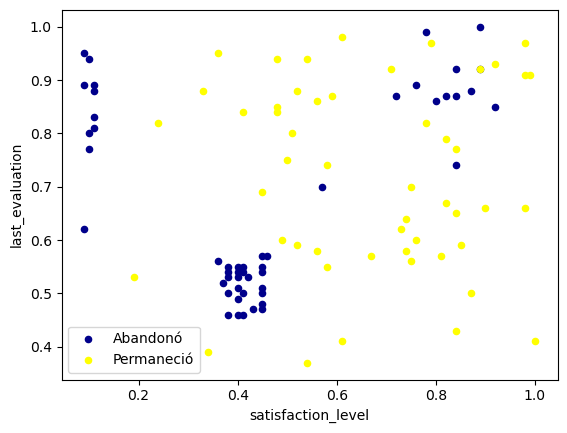

In [12]:
ax = cell_df[cell_df["left"] == 1][0:50].plot(kind = "scatter", x = "satisfaction_level", y = "last_evaluation", color = "DarkBlue", label = "Abandonó");
ax = cell_df[cell_df["left"] == 0][0:50].plot(kind = "scatter", x = "satisfaction_level", y = "last_evaluation", color = "Yellow", label = "Permaneció", ax = ax);
plt.show()

In [6]:
cell_df = pd.get_dummies(cell_df, columns = ["sales", "salary"], dtype = int)
cell_df

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales_IT,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0
1,0.80,0.86,5,262,6,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1
2,0.11,0.88,7,272,4,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1
3,0.72,0.87,5,223,5,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0
4,0.37,0.52,2,159,3,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0
14995,0.37,0.48,2,160,3,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0
14996,0.37,0.53,2,143,3,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0
14997,0.11,0.96,6,280,4,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0


In [7]:
cell_df.dtypes

satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
left                       int64
promotion_last_5years      int64
sales_IT                   int64
sales_RandD                int64
sales_accounting           int64
sales_hr                   int64
sales_management           int64
sales_marketing            int64
sales_product_mng          int64
sales_sales                int64
sales_support              int64
sales_technical            int64
salary_high                int64
salary_low                 int64
salary_medium              int64
dtype: object

In [8]:
feature_df = cell_df[["satisfaction_level", "last_evaluation", "number_project", "average_montly_hours", "time_spend_company", "Work_accident", "promotion_last_5years", "sales_IT", "sales_RandD", "sales_accounting", "sales_hr", "sales_management", "sales_marketing", "sales_product_mng", "sales_sales", "sales_support", "sales_technical", "salary_high", "salary_low", "salary_medium"]]
x = np.asarray(feature_df)
x[0:5]

array([[3.80e-01, 5.30e-01, 2.00e+00, 1.57e+02, 3.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        1.00e+00, 0.00e+00],
       [8.00e-01, 8.60e-01, 5.00e+00, 2.62e+02, 6.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 1.00e+00],
       [1.10e-01, 8.80e-01, 7.00e+00, 2.72e+02, 4.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 1.00e+00],
       [7.20e-01, 8.70e-01, 5.00e+00, 2.23e+02, 5.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        1.00e+00, 0.00e+00],
       [3.70e-01, 5.20e-01, 2.00e+00, 1.59e+02, 3.00e+00, 0.00e+00,


In [9]:
cell_df["left"] = cell_df["left"].astype("int")
y = np.asarray(cell_df["left"])
y[0:5]

array([1, 1, 1, 1, 1])

In [10]:
# Creación de grupos de entrenamiento y prueba
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size= 0.2, random_state = 4)
print("Grupo de entrenamiento", x_train.shape, y_train.shape)
print("Grupo de prueba",x_test.shape,y_test.shape)

Grupo de entrenamiento (11999, 20) (11999,)
Grupo de prueba (3000, 20) (3000,)


# Modelación con SVM

### Kernel RBF

In [11]:
from sklearn import svm
clf = svm.SVC(kernel = "rbf")
clf.fit(x_train, y_train)

# Predicción para la base de prueba
yhat = clf.predict(x_test)
yhat[0:5]

array([0, 0, 0, 0, 0])

In [12]:
# Creación de matriz de confusión
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(x)
cm = confusion_matrix(y_test,yhat)
cm

array([[2287,    0],
       [ 669,   44]])

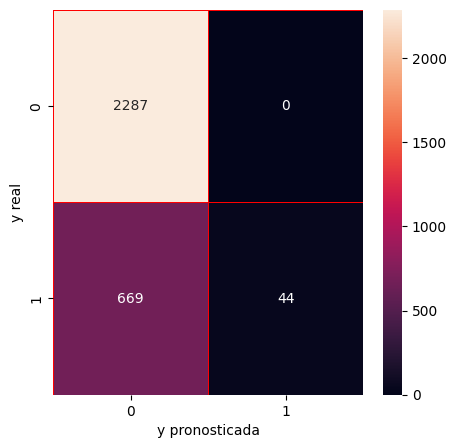

In [13]:
# Visualizar la matriz de confusión
import seaborn as sns
f, ax = plt.subplots(figsize = (5,5))
sns.heatmap(cm,annot=True, linewidths = 0.5, linecolor = "red", fmt = ".0f", ax = ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.show()

In [14]:
from sklearn.metrics import classification_report
cnf_matrix = confusion_matrix(y_test, yhat,labels = [0,1])
print(classification_report(y_test,yhat))

              precision    recall  f1-score   support

           0       0.77      1.00      0.87      2287
           1       1.00      0.06      0.12       713

    accuracy                           0.78      3000
   macro avg       0.89      0.53      0.49      3000
weighted avg       0.83      0.78      0.69      3000



### Interpretación de métricas con los cálculos 

In [15]:
precisionpermanecio = cm[0,0] / (cm[0,0] + cm[1,0])
precisionpermanecio

np.float64(0.773680649526387)

In [16]:
precisionabandono = cm[1,1] / (cm[1,1] + cm[0,1])
precisionabandono

np.float64(1.0)

In [17]:
recallpermanecio = cm[0,0] / (cm[0,0] + cm[0,1])
recallpermanecio

np.float64(1.0)

In [18]:
recallabandono = cm[1,1] / (cm[1,0] + cm[1,1])
recallabandono

np.float64(0.061711079943899017)

In [19]:
f1permanecio = 2 * (precisionpermanecio * recallpermanecio) / (precisionpermanecio + recallpermanecio)
f1permanecio

np.float64(0.8724012969673851)

In [20]:
f1abandono = 2 * (precisionabandono * recallabandono) / (precisionabandono + recallabandono)
f1abandono

np.float64(0.11624834874504625)

In [21]:
soportepermanecio = cm[0,0] + cm[0,1]
soportepermanecio

np.int64(2287)

In [22]:
soporteabandono = cm[1,0] + cm[1,1]
soporteabandono

np.int64(713)

In [23]:
correctos = cm[0,0] + cm[1,1]
incorrectos = cm[0,1] + cm[1,0]
precisionglobal = correctos / (correctos + incorrectos)
precisionglobal

np.float64(0.777)

In [24]:
macroavgprecision = (precisionpermanecio + precisionabandono) /2
macroavgprecision

np.float64(0.8868403247631935)

In [25]:
macroavgrecall = (recallpermanecio + recallabandono) /2
macroavgrecall

np.float64(0.5308555399719495)

In [26]:
macrof1score = (f1permanecio + f1abandono) /2
macrof1score

np.float64(0.4943248228562157)

In [27]:
pesopermanecio = soportepermanecio / (soportepermanecio + soporteabandono)
pesoabandono = soporteabandono / (soportepermanecio + soporteabandono)

In [28]:
wavgprecision = precisionpermanecio * pesopermanecio + precisionabandono * pesoabandono
wavgprecision

np.float64(0.8274692151556158)

In [29]:
wavgrecall = recallpermanecio * pesopermanecio + recallabandono * pesoabandono
wavgrecall

np.float64(0.777)

In [30]:
wavgf1score = f1permanecio * pesopermanecio + f1abandono * pesoabandono
wavgf1score

np.float64(0.6926889462732092)

### Kernel Polinomial

In [31]:
from sklearn import svm
clf = svm.SVC(kernel = "poly")
clf.fit(x_train, y_train)

# Predicción para la base de prueba
yhat = clf.predict(x_test)
yhat[0:5]

array([0, 0, 0, 0, 0])

In [32]:
# Creación de matriz de confusión
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(x)
cm = confusion_matrix(y_test,yhat)
cm

array([[2287,    0],
       [ 713,    0]])

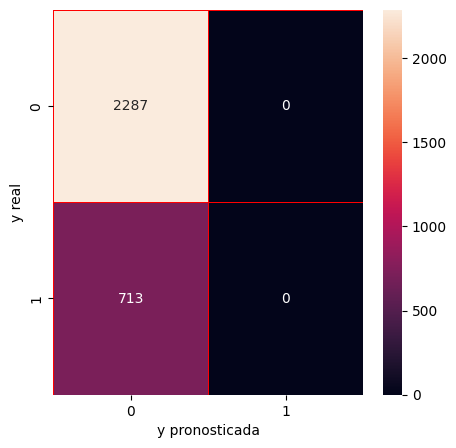

In [33]:
# Visualizar la matriz de confusión
import seaborn as sns
f, ax = plt.subplots(figsize = (5,5))
sns.heatmap(cm,annot=True, linewidths = 0.5, linecolor = "red", fmt = ".0f", ax = ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.show()

In [34]:
from sklearn.metrics import classification_report
cnf_matrix = confusion_matrix(y_test, yhat,labels = [0,1])
print(classification_report(y_test,yhat))

              precision    recall  f1-score   support

           0       0.76      1.00      0.87      2287
           1       0.00      0.00      0.00       713

    accuracy                           0.76      3000
   macro avg       0.38      0.50      0.43      3000
weighted avg       0.58      0.76      0.66      3000



### Kernel Sigmoide

In [35]:
from sklearn import svm
clf = svm.SVC(kernel = "sigmoid")
clf.fit(x_train, y_train)

# Predicción para la base de prueba
yhat = clf.predict(x_test)
yhat[0:5]

array([0, 0, 0, 0, 0])

In [36]:
# Creación de matriz de confusión
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(x)
cm = confusion_matrix(y_test,yhat)
cm

array([[1885,  402],
       [ 507,  206]])

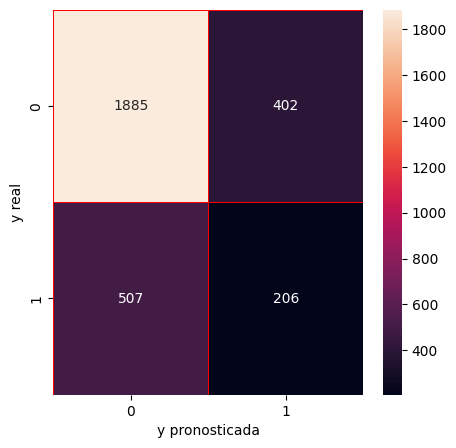

In [37]:
# Visualizar la matriz de confusión
import seaborn as sns
f, ax = plt.subplots(figsize = (5,5))
sns.heatmap(cm,annot=True, linewidths = 0.5, linecolor = "red", fmt = ".0f", ax = ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.show()

In [38]:
from sklearn.metrics import classification_report
cnf_matrix = confusion_matrix(y_test, yhat,labels = [0,1])
print(classification_report(y_test,yhat))

              precision    recall  f1-score   support

           0       0.79      0.82      0.81      2287
           1       0.34      0.29      0.31       713

    accuracy                           0.70      3000
   macro avg       0.56      0.56      0.56      3000
weighted avg       0.68      0.70      0.69      3000



### Kernel Lineal

In [39]:
from sklearn import svm
clf = svm.SVC(kernel = "linear")
clf.fit(x_train, y_train)

# Predicción para la base de prueba
yhat = clf.predict(x_test)
yhat[0:5]

array([0, 1, 0, 0, 0])

In [40]:
# Creación de matriz de confusión
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(x)
cm = confusion_matrix(y_test,yhat)
cm

array([[2149,  138],
       [ 522,  191]])

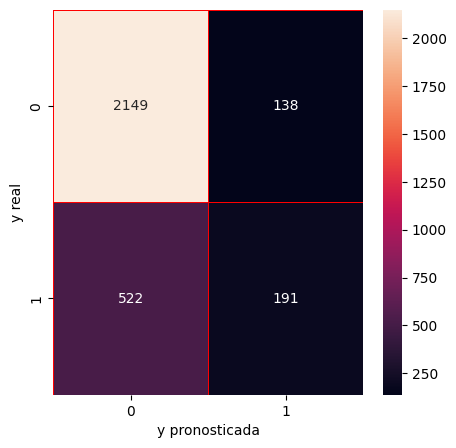

In [41]:
# Visualizar la matriz de confusión
import seaborn as sns
f, ax = plt.subplots(figsize = (5,5))
sns.heatmap(cm,annot=True, linewidths = 0.5, linecolor = "red", fmt = ".0f", ax = ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.show()

In [42]:
from sklearn.metrics import classification_report
cnf_matrix = confusion_matrix(y_test, yhat,labels = [0,1])
print(classification_report(y_test,yhat))

              precision    recall  f1-score   support

           0       0.80      0.94      0.87      2287
           1       0.58      0.27      0.37       713

    accuracy                           0.78      3000
   macro avg       0.69      0.60      0.62      3000
weighted avg       0.75      0.78      0.75      3000



### Decisión de modelo y pronóstico

In [43]:
feature_df.columns

Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'average_montly_hours', 'time_spend_company', 'Work_accident',
       'promotion_last_5years', 'sales_IT', 'sales_RandD', 'sales_accounting',
       'sales_hr', 'sales_management', 'sales_marketing', 'sales_product_mng',
       'sales_sales', 'sales_support', 'sales_technical', 'salary_high',
       'salary_low', 'salary_medium'],
      dtype='object')

In [44]:
nuevo_empleado = np.asarray([[0.5, 0.75, 4, 200, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1]])
pronostico = clf.predict(nuevo_empleado)
print("Pronóstico para el empleado (1 = abandonó, 0 = permaneció):", pronostico[0])

Pronóstico para el empleado (1 = abandonó, 0 = permaneció): 0
